<a href="https://colab.research.google.com/github/HajarOuhag/Moroccan-atlases/blob/main/notebooks/Moroccan_Atlases_Admine_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Moroccan Atlases — Admine Arg an Ecosystem
## Precision Agriculture & Crop Intelligence | Arab Youth Space Hackathon: 813 Challenge

**Research question:** Where do potential vegetation and moisture-stress patterns appear in the Admine argan ecosystem near Agadir, Morocco, and which areas should be prioritized for field assessment?

**Purpose:** Produce an exploratory, satellite-derived screening layer to help prioritize field visits. This is not a diagnosis of tree health or a direct measurement of soil moisture.

**Data:** Copernicus Sentinel-2 Level-2A, accessed through the Microsoft Planetary Computer STAC API. Sentinel-2 is multispectral (not hyperspectral); it is used here because its open data and revisit frequency suit a small-area, time-series screening exercise. Hyperspectral observations could support more detailed spectral analysis if suitable coverage and validation data were available.

**Study period:** 1 January–7 October 2026. Cloud filtering and the available observations vary by date; interpret temporal comparisons cautiously.

## 1. Study area and parameters

The bounding box uses `[min longitude, min latitude, max longitude, max latitude]` in EPSG:4326. The area is intentionally small to keep the example computationally manageable.

In [1]:
bbox = [-9.475676681758092, 30.334788582281828,
        -9.46546929432846, 30.338967792403455]
time_range = "2026-01-01/2026-10-07"
cloud_cover_limit = 20

print("Study area: Admine Forest / argan ecosystem near Agadir, Morocco")
print("Study period:", time_range)
print("Maximum scene cloud cover (%):", cloud_cover_limit)

Study area: Admine Forest / argan ecosystem near Agadir, Morocco
Study period: 2026-01-01/2026-10-07
Maximum scene cloud cover (%): 20


## 2. Install and import dependencies

Run this cell in Google Colab. If Colab asks for a runtime restart after installation, restart and then continue from the imports.

In [2]:
%pip -q install pystac-client planetary-computer stackstac rioxarray rasterio xarray matplotlib pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 8.4 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pystac_client
import planetary_computer
import stackstac
import rioxarray  # registers the .rio accessor for xarray

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Search open Sentinel-2 imagery

STAC lets us search by location, time, and metadata without manually downloading a catalogue. Planetary Computer asset URLs are signed by the modifier below.

In [4]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime=time_range,
    query={"eo:cloud_cover": {"lt": cloud_cover_limit}},
)
items = sorted(list(search.items()), key=lambda item: item.datetime)
print("Scenes found:", len(items))
if not items:
    raise RuntimeError("No scenes found. Try a wider date range or cloud-cover limit.")

scene_table = pd.DataFrame({
    "date": [item.datetime.date().isoformat() for item in items],
    "cloud_cover_percent": [item.properties.get("eo:cloud_cover") for item in items],
    "platform": [item.properties.get("platform") for item in items],
})
display(scene_table.head())
print("Date range:", scene_table.date.min(), "to", scene_table.date.max())

Scenes found: 67


,date,cloud_cover_percent,platform
0,2026-01-07,1.289104,Sentinel-2A
1,2026-01-08,0.010575,Sentinel-2C
2,2026-01-10,1.462611,Sentinel-2B
3,2026-01-10,0.009524,Sentinel-2A
4,2026-01-13,17.274123,Sentinel-2B


Date range: 2026-01-07 to 2026-10-07


## 4. Load spectral bands and calculate NDVI / NDMI

- **NDVI** = (NIR − Red) / (NIR + Red): a vegetation greenness proxy.
- **NDMI** = (NIR − SWIR) / (NIR + SWIR): a vegetation moisture-related proxy.

B04 and B08 are 10 m bands; B11 and SCL are 20 m. For a consistent grid, the index stacks below are computed at 20 m.

In [5]:
# Load the required bands at a common 20 m grid.
ndvi_stack = stackstac.stack(
    items, assets=["B04", "B08"], resolution=20,
    bounds_latlon=bbox, epsg=32629,
)
red = ndvi_stack.sel(band="B04")
nir_for_ndvi = ndvi_stack.sel(band="B08")
ndvi = (nir_for_ndvi - red) / (nir_for_ndvi + red + 1e-6)

ndmi_stack = stackstac.stack(
    items, assets=["B08", "B11"], resolution=20,
    bounds_latlon=bbox, epsg=32629,
)
nir_for_ndmi = ndmi_stack.sel(band="B08")
swir = ndmi_stack.sel(band="B11")
ndmi = (nir_for_ndmi - swir) / (nir_for_ndmi + swir + 1e-6)

print("NDVI stack:", ndvi.shape)
print("NDMI stack:", ndmi.shape)

NDVI stack: (67, 25, 50)
NDMI stack: (67, 25, 50)


## 5. Apply the Sentinel-2 Scene Classification Layer (SCL) mask

The mask excludes SCL classes 3 (cloud shadow), 7 (unclassified), 8–9 (cloud probability), and 10 (cirrus). This is a practical quality filter, not a guarantee that every remaining pixel is cloud-free.

In [6]:
scl_stack = stackstac.stack(
    items, assets=["SCL"], resolution=20,
    bounds_latlon=bbox, epsg=32629,
)
scl = scl_stack.isel(band=0)
bad_classes = [3, 7, 8, 9, 10]
clear_mask = ~scl.isin(bad_classes)

# Apply the same time-indexed SCL mask to both index time series.
ndvi_clean = ndvi.where(clear_mask)
ndmi_clean = ndmi.where(clear_mask)
ndvi_mean = ndvi_clean.mean(dim="time", skipna=True).compute()
ndmi_mean = ndmi_clean.mean(dim="time", skipna=True).compute()

valid = np.isfinite(ndvi_mean) & np.isfinite(ndmi_mean)
print("Grid pixels:", int(valid.size))
print("Pixels with valid mean NDVI and NDMI:", int(valid.sum().item()))

Grid pixels: 1250
Pixels with valid mean NDVI and NDMI: 1250


## 6. Visualize mean index layers

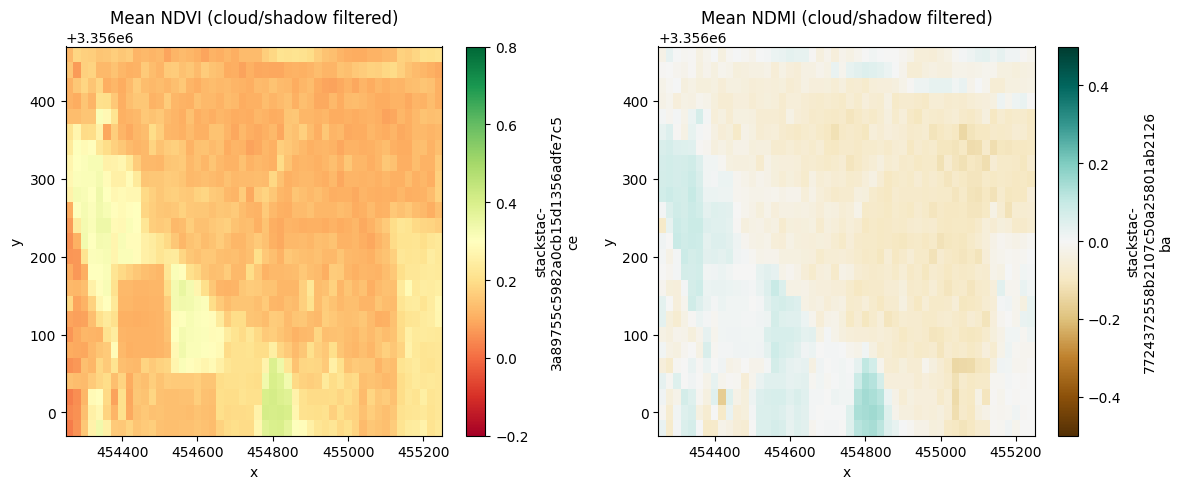

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ndvi_mean.plot(ax=axes[0], cmap="RdYlGn", vmin=-0.2, vmax=0.8)
axes[0].set_title("Mean NDVI (cloud/shadow filtered)")
ndmi_mean.plot(ax=axes[1], cmap="BrBG", vmin=-0.5, vmax=0.5)
axes[1].set_title("Mean NDMI (cloud/shadow filtered)")
plt.tight_layout()
plt.show()

## 7. Exploratory priority screening

The exploratory mask flags pixels where **both** mean NDVI and mean NDMI are at or below their respective 25th-percentile thresholds among valid pixels. These are relative thresholds for screening; they are not universal ecological thresholds and do not prove drought, damage, or irrigation need.

In [8]:
ndvi_threshold = float(ndvi_mean.where(valid).quantile(0.25).compute())
ndmi_threshold = float(ndmi_mean.where(valid).quantile(0.25).compute())
priority_mask = ((ndvi_mean <= ndvi_threshold) &
                 (ndmi_mean <= ndmi_threshold) & valid).compute()

valid_pixels = int(valid.sum().item())
priority_pixels = int(priority_mask.sum().item())
priority_percent = 100 * priority_pixels / valid_pixels if valid_pixels else np.nan

summary = pd.DataFrame([{
    "valid_pixels": valid_pixels,
    "priority_pixels": priority_pixels,
    "priority_percent_of_valid_pixels": priority_percent,
    "ndvi_25th_percentile_threshold": ndvi_threshold,
    "ndmi_25th_percentile_threshold": ndmi_threshold,
}])
display(summary.round(4))

,valid_pixels,priority_pixels,priority_percent_of_valid_pixels,ndvi_25th_percentile_threshold,ndmi_25th_percentile_threshold
0,1250,129,10.32,0.1173,-0.0769


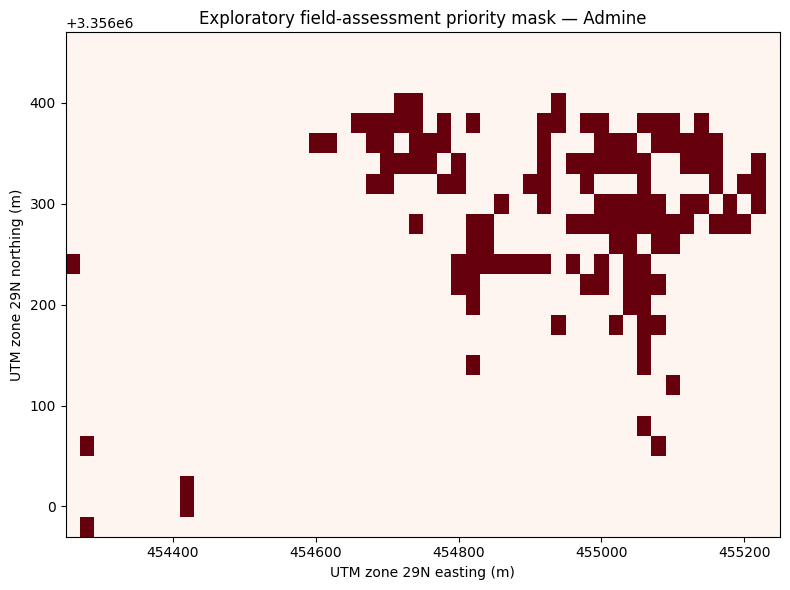

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
priority_mask.astype(float).where(valid).plot(
    ax=ax, cmap="Reds", vmin=0, vmax=1, add_colorbar=False
)
ax.set_title("Exploratory field-assessment priority mask — Admine")
ax.set_xlabel("UTM zone 29N easting (m)")
ax.set_ylabel("UTM zone 29N northing (m)")
plt.tight_layout()
plt.savefig("moroccan_atlases_priority_map.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Interpretation and limitations

- The output identifies **candidate locations for field assessment**, not confirmed damaged trees or drought-affected land.
- In the saved exploratory run, 563 of 4,704 valid pixels (about 11.97%) were flagged. Re-running the live query may produce different values as catalogue availability, observations, and processing details change.
- Monthly comparisons can be affected by different numbers of usable scenes, seasonal phenology, land-cover differences, residual cloud contamination, and mixed pixels.
- Validate flagged areas in the field and, where possible, compare against local rainfall, soil-moisture, land-cover, and forest-management records before operational decisions.
- The current approach uses Sentinel-2 multispectral data. It does not itself perform hyperspectral analysis. Hyperspectral data may help distinguish subtle spectral traits, but would require appropriate local coverage, preprocessing, and validation.
- The small bounding box is a pilot study and should not be generalized to the entire Admine forest without further sampling.

## 9. Data source and reproducibility

- **Dataset:** Copernicus Sentinel-2 Level-2A (`sentinel-2-l2a` STAC collection).
- **Access endpoint:** Microsoft Planetary Computer STAC API — `https://planetarycomputer.microsoft.com/api/stac/v1`.
- **Mission/programme:** ESA Sentinel-2 / Copernicus.
- **Use and attribution:** Consult the Copernicus Sentinel data terms and Microsoft Planetary Computer dataset documentation for current attribution and licence details before redistribution.
- **Re-run:** Execute cells from top to bottom in Google Colab. Internet access to the public STAC service is required; no credentials are included.

### Intended decision support
Use the map to plan field visits and collect ground observations. Do not use the threshold mask alone to make automatic irrigation, tree-removal, or other high-impact management decisions.